# 응용 07 · 이미지·영상 처리와 Gaussian·Median 비교

현재 `07_project.py`의 A07·A08을 실행하고 원본·처리 결과를 검증합니다. 추가 비교는 같은 160×120 그레이스케일 입력에 무필터·Gaussian 3×3·Median 3×3을 적용합니다. Python 파일의 필수 Gaussian 경로는 변경하지 않습니다.

필요 패키지: `opencv-python`, `numpy`, `pandas`, `matplotlib`, `IPython`. 패키지가 설치된 커널에서 순서대로 실행하세요. 원본은 보존하며 `outputs/p07_` 파일과 `result_summary.csv`는 다시 생성합니다.

## 1. 동작 구조

`process_image`: BGR 원본 → Gray → 160×120 Resize → Gaussian 3×3, sigmaX=0 → Canny 80/160 → gray·small·edge 반환.

`process_frame`: 같은 함수를 호출 → 세 번째 반환값 edge 선택 → `COLOR_GRAY2BGR` → 영상 Writer 전달.

Canny 출력은 `(120, 160)`의 uint8 단일 채널이며 값은 0 또는 255입니다. BGR 변환 후 `(120, 160, 3)`이 되고 각 채널은 동일합니다. 색상을 복원하는 변환은 아닙니다.

원본 코드의 Resize는 기본 보간법인 INTER_LINEAR를 사용합니다. `small` 옆의 ‘3x3 변환’ 주석은 실제 동작과 다르며, 3×3은 다음 Gaussian 커널의 크기입니다.

In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/02_응용/07_project.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/02_응용"


## 2. 현재 구현 실행

현재 파일을 그대로 사용하며, 노트북에서는 `__file__` 경로만 대체합니다. 이미지별 3단계 PNG 9개, 비교 PNG 3개, 영상 1개, 요약 CSV를 생성합니다. CSV의 process_s는 이미지 한 장의 전체 함수 실행시간이며 세 단계 행에 같은 값이 기록됩니다. 세 행을 더하면 처리시간이 중복 집계됩니다.

In [2]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

import csv
import json
from time import perf_counter
Path("outputs").mkdir(exist_ok=True)

def process_image(image):
    """원본 배열 → Gray·Resize·Edge. 파일 읽기는 호출한 쪽에서 합니다."""
    # >>> TODO A07
    # Gray→160×120 Resize→3×3 Gaussian→Canny 80/160을 구현하세요. 반환 변수 gray·small·edge를 만듭니다.
    gray = cv2.cvtColor(src=image, code=cv2.COLOR_BGR2GRAY)
    small = cv2.resize(gray, (160, 120)) # 3x3 변환
    gaussian = cv2.GaussianBlur(src=small, ksize=(3,3), sigmaX=0)
    edge = cv2.Canny(image=gaussian, threshold1=80, threshold2=160)
    # <<< TODO A07
    return gray, small, edge

def process_frame(frame):
    """Writer가 받을 160×120 BGR 프레임을 반환합니다."""
    # >>> TODO A08
    # process_image(frame)의 세 번째 반환값 edge를 받아 3채널 BGR로 변환해 반환하세요.
    _, _, edge = process_image(frame)
    return cv2.cvtColor(src=edge, code=cv2.COLOR_GRAY2BGR)
    # <<< TODO A08

rows = []
for filename in ["scene.png", "noisy.png", "objects.png"]:
    image = cv2.imread("data/" + filename)
    start = perf_counter(); gray, small, edge = process_image(image); seconds = perf_counter()-start
    stem = Path(filename).stem
    for stage, result in [("gray", gray), ("small", small), ("edge", edge)]:
        path = f"outputs/p07_{stem}_{stage}.png"; saved = cv2.imwrite(path, result)
        reread = cv2.imread(path, cv2.IMREAD_UNCHANGED)
        rows.append([filename, stage, result.shape[1], result.shape[0], str(result.dtype), saved, np.array_equal(result,reread), seconds])
    preview = cv2.hconcat([cv2.resize(image,(160,120)), cv2.cvtColor(small,cv2.COLOR_GRAY2BGR), cv2.cvtColor(edge,cv2.COLOR_GRAY2BGR)])
    cv2.imwrite(f"outputs/p07_{stem}_compare.png", preview)
cap=cv2.VideoCapture("data/sample.avi"); fps=cap.get(cv2.CAP_PROP_FPS)
writer=cv2.VideoWriter("outputs/p07_video.avi", cv2.VideoWriter_fourcc(*"MJPG"),fps,(160,120))
count=0
while cap.isOpened() and writer.isOpened():
    ok, frame=cap.read()
    if not ok: break
    writer.write(process_frame(frame)); count+=1
cap.release();writer.release()
with open("outputs/result_summary.csv","w",encoding="utf-8-sig",newline="") as f:
    w=csv.writer(f);w.writerow(["source","stage","width","height","dtype","saved","png_equal","process_s"]);w.writerows(rows)
check=cv2.VideoCapture("outputs/p07_video.avi")
print("이미지 처리표:",len(rows),"행 / 원본3장")
print("Frame 처리/재읽기:",count,int(check.get(cv2.CAP_PROP_FRAME_COUNT)))
print("재읽기 크기/FPS:",int(check.get(3)),int(check.get(4)),check.get(5));check.release()
print("PNG 저장·재읽기 모두 일치:",all(r[5] and r[6] for r in rows))


이미지 처리표: 9 행 / 원본3장
Frame 처리/재읽기: 48 48
재읽기 크기/FPS: 160 120 12.0
PNG 저장·재읽기 모두 일치: True


## 3. 원본·필터 결과 비교표

원본은 320×240 BGR입니다. 필터 비교 기준은 원본을 Gray로 바꾸고 160×120으로 축소한 동일 배열입니다. 서로 크기나 의미가 다른 원본 컬러와 Edge 사이의 MSE를 계산하지 않습니다.

- Edge 수는 모든 행에서 같은 Canny 80/160으로 계산합니다.
- Edge 차이는 **각 처리의 Edge 수 − 무필터 Edge 수**입니다.
- 필터 MSE는 **필터 영상과 축소 Gray의 차이**입니다. 축소 자체의 손실이나 모델 성능이 아닙니다.
- 시간은 Gray·Resize·해당 필터·Canny를 포함한 단일 호출 측정값이며 파일 읽기·저장을 제외합니다. 실행 부하와 초기 실행 비용 등의 영향을 받으므로 속도 순위를 확정하는 값이 아닙니다.

In [3]:
originals = {}
filter_results = {}
comparison_rows = []
original_rows = []
for filename in ["scene.png", "noisy.png", "objects.png"]:
    original = cv2.imread("data/" + filename)
    assert original is not None
    originals[filename] = original.copy()
    baseline = cv2.resize(cv2.cvtColor(original, cv2.COLOR_BGR2GRAY), (160, 120))
    base_edges = int(np.count_nonzero(cv2.Canny(baseline, 80, 160)))
    original_rows.append({"이미지": filename, "원본 크기 (W×H)": f"{original.shape[1]}×{original.shape[0]}",
                          "원본 채널": original.shape[2], "결과 크기 (W×H)": "160×120",
                          "Edge 채널": 1, "영상 저장용 채널": 3, "dtype": str(original.dtype)})
    for method in ["none", "gaussian", "median"]:
        start = perf_counter()
        gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
        small = cv2.resize(gray, (160, 120))
        if method == "gaussian":
            filtered = cv2.GaussianBlur(small, (3, 3), 0)
        elif method == "median":
            filtered = cv2.medianBlur(small, 3)
        else:
            filtered = small.copy()
        edge = cv2.Canny(filtered, 80, 160)
        elapsed_ms = (perf_counter() - start) * 1000
        filter_results[(filename, method)] = (filtered, edge)
        edge_count = int(np.count_nonzero(edge))
        comparison_rows.append({"이미지": filename, "처리": method, "크기 (W×H)": "160×120",
                                "Edge 픽셀 수": edge_count, "무필터 대비 Edge 차이": edge_count - base_edges,
                                "축소 Gray 대비 필터 MSE": round(float(np.mean((filtered.astype(np.float32) - baseline.astype(np.float32)) ** 2)), 4),
                                "전체 함수 처리시간 (ms)": round(elapsed_ms, 6)})
original_comparison = pd.DataFrame(original_rows)
filter_comparison = pd.DataFrame(comparison_rows)
display(original_comparison)
display(filter_comparison)
edge_table = filter_comparison.pivot(index="이미지", columns="처리", values="Edge 픽셀 수").reindex(columns=["none", "gaussian", "median"])
edge_table["Median - Gaussian"] = edge_table["median"] - edge_table["gaussian"]
display(edge_table)

,이미지,원본 크기 (W×H),원본 채널,결과 크기 (W×H),Edge 채널,영상 저장용 채널,dtype
0,scene.png,320×240,3,160×120,1,3,uint8
1,noisy.png,320×240,3,160×120,1,3,uint8
2,objects.png,320×240,3,160×120,1,3,uint8


,이미지,처리,크기 (W×H),Edge 픽셀 수,무필터 대비 Edge 차이,축소 Gray 대비 필터 MSE,전체 함수 처리시간 (ms)
0,scene.png,none,160×120,1454,0,0.0000,0.087565
1,scene.png,gaussian,160×120,1445,-9,87.8940,0.096882
2,scene.png,median,160×120,1209,-245,79.9563,0.073215
3,noisy.png,none,160×120,2476,0,0.0000,0.057271
4,noisy.png,gaussian,160×120,1424,-1052,153.3307,0.052705
5,noisy.png,median,160×120,1199,-1277,185.3719,0.190026
6,objects.png,none,160×120,433,0,0.0000,0.044079
7,objects.png,gaussian,160×120,444,11,101.0685,0.043234
8,objects.png,median,160×120,426,-7,34.0542,0.045956


처리,none,gaussian,median,Median - Gaussian
이미지,,,,
noisy.png,2476,1424,1199,-225
objects.png,433,444,426,-18
scene.png,1454,1445,1209,-236


## 4. 이미지별 원본·필터·Edge 비교

각 이미지의 위쪽은 원본 컬러와 같은 크기의 비교용 축소 Gray·Gaussian·Median, 아래쪽은 각 필터 결과의 Canny입니다. 원본은 표시 영역에 맞춰 보이며 실제 크기는 위 표에 기록했습니다.

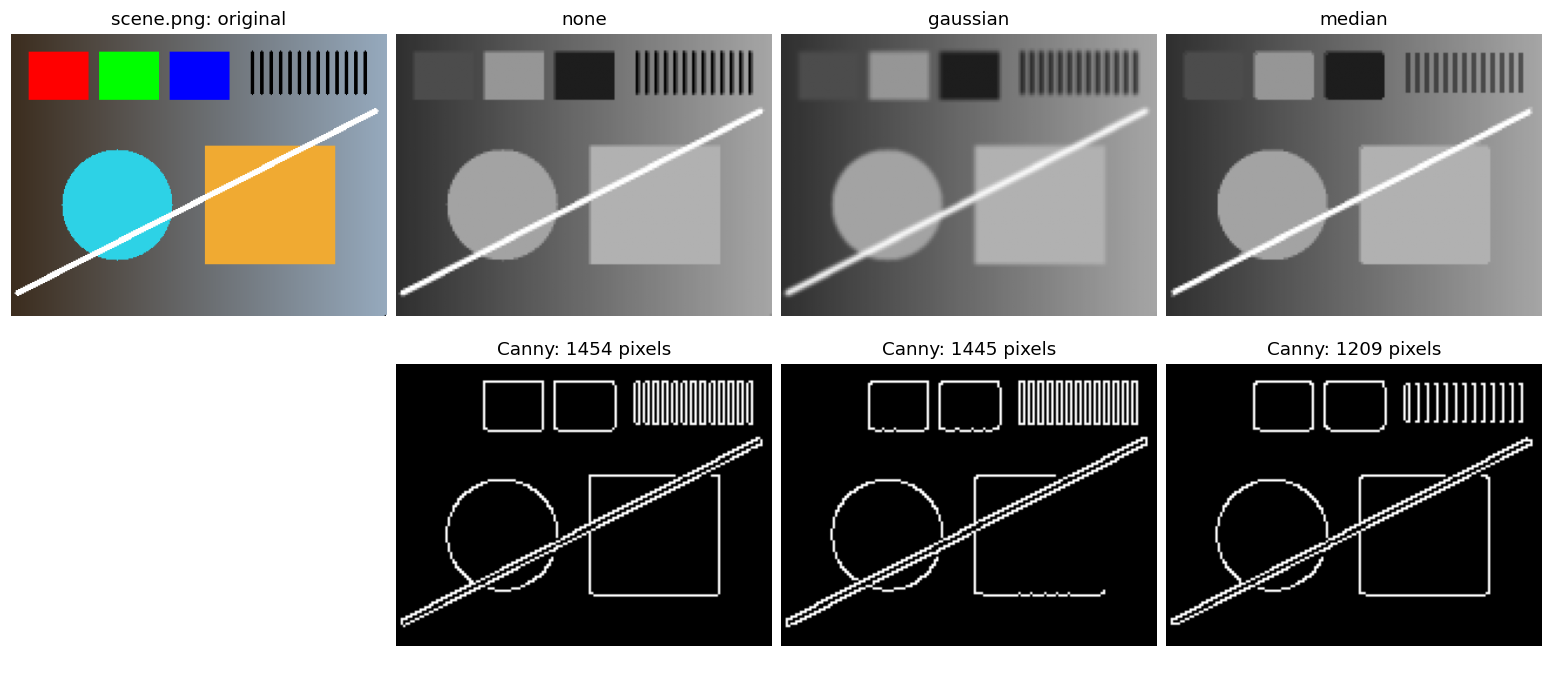

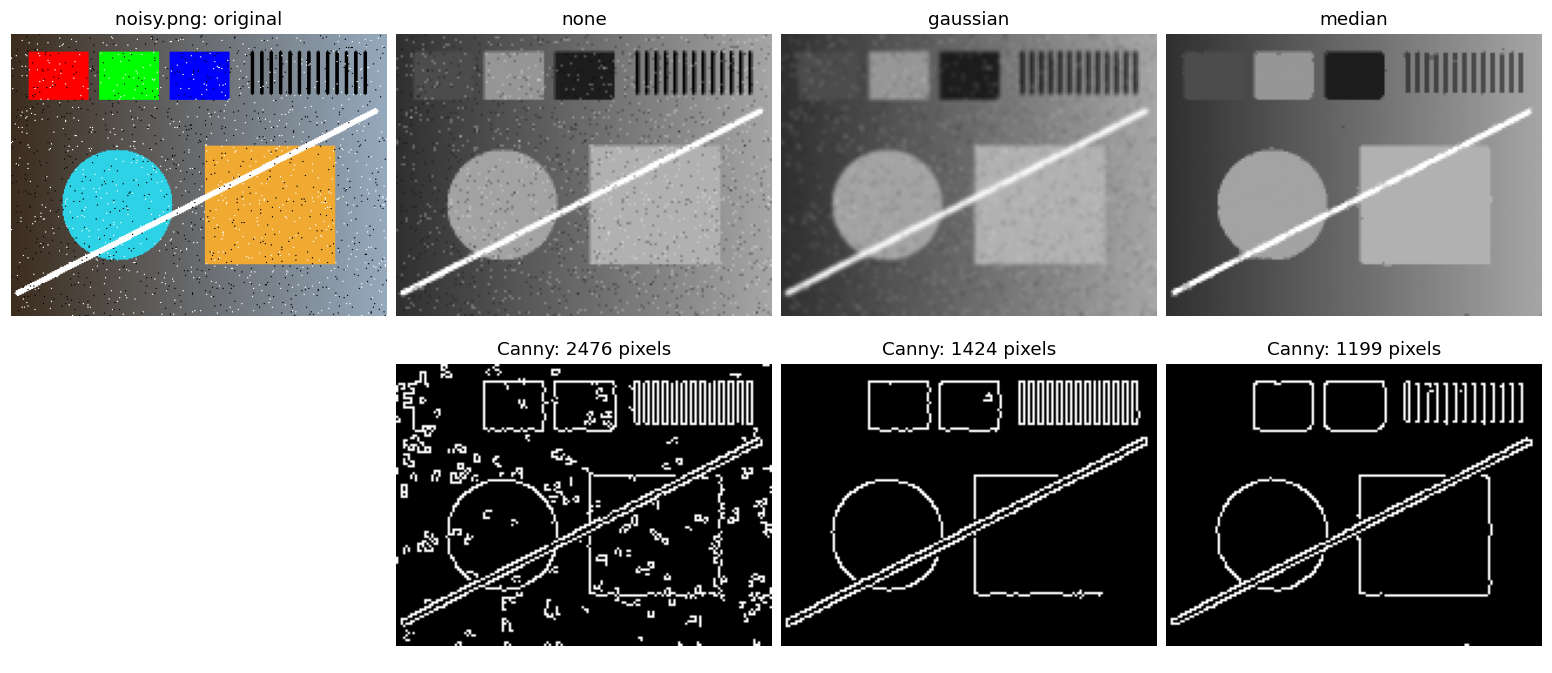

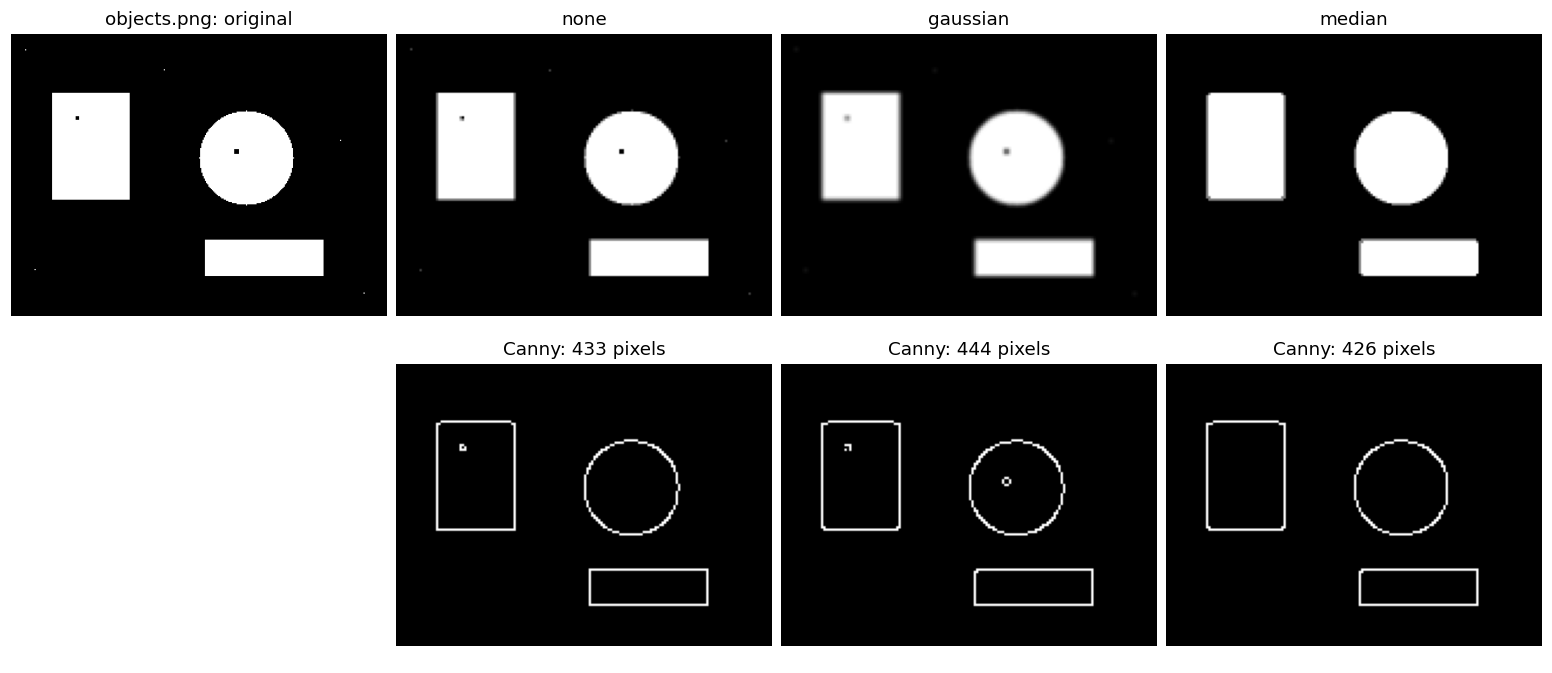

In [4]:
for filename, original in originals.items():
    fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True)
    axes[0, 0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title(f"{filename}: original")
    axes[1, 0].axis("off")
    for col, method in enumerate(["none", "gaussian", "median"], 1):
        filtered, edge = filter_results[(filename, method)]
        axes[0, col].imshow(filtered, cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(method)
        axes[1, col].imshow(edge, cmap="gray", vmin=0, vmax=255)
        axes[1, col].set_title(f"Canny: {np.count_nonzero(edge)} pixels")
    for ax in axes.flat: ax.axis("off")
    plt.show()

## 5. 원본 대비 산출물 검증표

이미지 3장의 각 단계와 저장 PNG를 재계산 결과와 비교합니다. 영상은 원본과 출력 모두 끝까지 디코딩하여 프레임 수·크기·FPS를 확인합니다. MJPG는 손실 압축이므로 디코딩 영상이 저장 전 Edge 배열과 픽셀 단위로 같다고 검증하지 않습니다.

In [5]:
saved_summary = pd.read_csv("outputs/result_summary.csv")
assert len(saved_summary) == 9
validation_rows = []
for filename, original in originals.items():
    snapshot = original.copy()
    gray, small, edge = process_image(original)
    frame = process_frame(original)
    for stage, result in [("gray", gray), ("small", small), ("edge", edge)]:
        saved_image = cv2.imread(f"outputs/p07_{Path(filename).stem}_{stage}.png", cv2.IMREAD_UNCHANGED)
        validation_rows.append({"입력": filename, "단계": stage, "shape": str(result.shape),
                                "원본 보존": np.array_equal(original, snapshot),
                                "저장 PNG 일치": np.array_equal(result, saved_image)})
    assert edge.shape == (120, 160)
    assert set(np.unique(edge)).issubset({0, 255})
    assert np.array_equal(edge, filter_results[(filename, "gaussian")][1])
    assert frame.shape == (120, 160, 3)
    assert np.array_equal(frame, cv2.cvtColor(edge, cv2.COLOR_GRAY2BGR))
image_validation = pd.DataFrame(validation_rows)
display(image_validation)
assert image_validation[["원본 보존", "저장 PNG 일치"]].all().all()

video_rows = []
for label, path in [("원본", "data/sample.avi"), ("처리", "outputs/p07_video.avi")]:
    capture = cv2.VideoCapture(path)
    assert capture.isOpened()
    fps_value = capture.get(cv2.CAP_PROP_FPS)
    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    decoded = 0
    while True:
        ok, frame = capture.read()
        if not ok: break
        assert frame.shape == (height, width, 3)
        decoded += 1
    capture.release()
    video_rows.append({"영상": label, "FPS": fps_value, "크기 (W×H)": f"{width}×{height}",
                       "실제 디코딩 프레임 수": decoded, "재생시간 (초)": decoded / fps_value})
video_validation = pd.DataFrame(video_rows)
display(video_validation)
assert video_validation["FPS"].tolist() == [12, 12]
assert video_validation["실제 디코딩 프레임 수"].tolist() == [48, 48]
assert video_validation["크기 (W×H)"].tolist() == ["320×240", "160×120"]
assert len(list(Path("outputs").glob("p07_*_compare.png"))) == 3
print("검증 통과: A07·A08, PNG 9개·비교 PNG 3개·영상 프레임/FPS/크기")
os.chdir(notebook_start)

,입력,단계,shape,원본 보존,저장 PNG 일치
0,scene.png,gray,"(240, 320)",True,True
1,scene.png,small,"(120, 160)",True,True
2,scene.png,edge,"(120, 160)",True,True
3,noisy.png,gray,"(240, 320)",True,True
4,noisy.png,small,"(120, 160)",True,True
5,noisy.png,edge,"(120, 160)",True,True
6,objects.png,gray,"(240, 320)",True,True
7,objects.png,small,"(120, 160)",True,True
8,objects.png,edge,"(120, 160)",True,True


,영상,FPS,크기 (W×H),실제 디코딩 프레임 수,재생시간 (초)
0,원본,12.0,320×240,48,4.0
1,처리,12.0,160×120,48,4.0


검증 통과: A07·A08, PNG 9개·비교 PNG 3개·영상 프레임/FPS/크기


## 해석

Gaussian은 주변 픽셀의 가중 평균, Median은 이웃의 중앙값을 사용합니다. 두 필터 모두 이 비교에서는 3×3이며 Canny 조건도 같습니다. 결과 차이는 입력의 잡음과 경계 형태에 따라 달라집니다.

Edge 수 감소는 잡음 경계 감소와 실제 세부 경계 손실을 함께 포함할 수 있습니다. Edge 수나 MSE만으로 어느 필터가 가장 좋다고 결론 내리지 않습니다. 이미지와 표를 함께 보고 판단합니다.

Median 비교는 이미지 3장의 추가 실험입니다. 저장 영상은 현재 과제의 Gaussian 경로이며 Median 영상으로 표시하지 않습니다.

## 모델 선정 결과 및 개인적 견해

결론: noisy.png, objects.png의 손실을 고려하여 모델을 선정했을 때 Gaussian이 적합하다고 판단했습니다.

### 판단 근거
- 노이즈가 제거 됐는가?
- Object의 경계가 유지되는가?

### 노이즈 제거 기준

노이즈 제거의 경우 Gaussian 보다 Median이 더 효과적으로 관측됐습니다.     
Gaussian와 None의 경우 노이즈가 일부 제거되지 않거나 Edge가 손실되는 경우가 관측 됐으나, Median의 경우 노이즈가 모두 제거되면서 모든 객체의 Edge가 유지되는 것을 확인했습니다.

### Object 경계 유지 기준

Object 경계 유지의 경우 Gaussian이 더 효과적으로 관측됐습니다.    
Median의 경우 객체 내 작은 원에 대해서 모두 노이즈로 판단해서 제거하는 경향이 관측 됐습니다.    
None의 경우 사각형 내부의 작은 원은 유지 됐으나, 원형 내부의 작은 원은 제거되는 것이 관측되어 동일하게 손실이 발생했습니다.    

마지막으로 Gaussian의 경우 모든 객체 내 작은 원이 유지 되는 것으로 확인되어 Gaussian이 Object 경계 유지에 더 적합하다고 판단했습니다.

## 최종 정리

해당 내용을 기반으로 정리 했을 때 노이즈 제거 시 Edge에 대한 손실이 발생했으나, Object의 형태 유지가 더욱 중요하다고 판단하여 위 내용을 종합하여 Gaussian을 최종 모델로 선정했습니다.    
이 내용은 전처리 과정을 하나로만 제한 했을 때 기준으로 작성됐으며, 추후 Median과 Gaussian을 조합하여 전처리 과정을 진행하거나 노이즈가 발생된 이미지와 일반 이미지를 구분하여 전처리를 적용할 경우 전처리 기준을 다르게 설정하여 더욱 향상된 결과가 나올 것을 기대합니다.